# 04 신마법공식 (PBR + GP/A)

## 0. 원문 정리
> **책 원문 미확인 — 정의는 2차 인용, 나머지 설정은 우동호 설정을 따름.**
> 강환국(2017) 10장 원문이 없어 종목 수·리밸런싱·가중 같은 책의 숫자는 쓰지 않는다(지어내지 않음).

| 항목 | 정의 | 출처 | 우리 설정 |
|---|---|---|---|
| 지표 | PBR 순위(낮을수록 좋음) + GP/A 순위(높을수록 좋음) 합산 | 2차 인용 | `지표=[("BP","높게"),("GPA","높게")]`, `합산="순위합산"` |
| PBR | 시가총액 / 자기자본 | — | `BP` = 자본총계(지배) / 시가총액의 역수 꼴. 낮은 PBR = 높은 BP(자본이 음수인 종목만 순서가 다름 → 아래 '다르게 한 것') |
| GP/A | (매출액 − 매출원가) / 자산총계 | Novy-Marx(2013) | `GPA` |
| 나머지 | 우동호 외(2023) IMF와 똑같이 | 우동호 p.512–513 | `포.우동호2023`: 유가+코스닥, 금융업·투자기구·12월 결산 아님·거래정지 제외, 4월 첫 거래일, 상위 30종목, 동일가중, 같은 거래비용(전량교체), 수정주가, 국고3년 |

참고(9절 뒤): Novy-Marx(2013) 4.3.1절·표 7 Panel C 설정(비금융 대형주 500, GP/A + B/M 순위 평균, 3묶음, 6월 말 연 1회)으로도 돌려 원문 숫자와 비교한다.

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 1. 불러오기
계산은 모두 `공통/` 폴더의 모듈이 한다. 이 노트북은 설정을 정하고, 실행하고, 결과를 본다.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import pandas as pd
import 데이터읽기 as 읽기, 종목거르기, 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

## 2. 데이터 경로와 기간
데이터를 어디서 읽을지, 어느 기간을 돌릴지 정한다. 기간은 (첫 리밸런싱 월, 마지막 기준일 월)이다.

In [2]:
# 합친 파일(읽기.DATA 기본 = data\통합_202611)로 원문 기간을 돌린다.
# 시험 데이터로 빨리 볼 때: 읽기.DATA = Path.cwd().parent / "_시험데이터"; 기간 = ("2004-04", "2006-12")
기간 = ("2004-04", "2022-04")
print("데이터:", 읽기.DATA, "/ 기간:", 기간)

데이터: D:\26-2_데이터기반투자전략\과제02\data\통합_202611 / 기간: ('2004-04', '2022-04')


## 3. 설정
신마법공식과, 같은 설정의 우동호 IMF(GP/A + EY)를 나란히 돌린다.

In [3]:
설정 = {"신마법공식": {**포.우동호2023, "이름": "신마법공식", "기간": 기간, "지표": [("BP", "높게"), ("GPA", "높게")]},
        "우동호IMF": {**포.우동호2023, "이름": "우동호2023_IMF", "기간": 기간, "지표": [("GPA", "높게"), ("EY", "높게")]}}
pd.DataFrame(설정).astype(str)

,신마법공식,우동호IMF
시장,"['KS', 'KQ']","['KS', 'KQ']"
가격,S410000700,S410000700
기간,"('2004-04', '2022-04')","('2004-04', '2022-04')"
기준일,첫거래일,첫거래일
리밸런싱,12,12
재무시점,"('결산후개월', 3)","('결산후개월', 3)"
제외,"['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래...","['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래..."
지표,"[('BP', '높게'), ('GPA', '높게')]","[('GPA', '높게'), ('EY', '높게')]"
합산,순위합산,순위합산
고르기,"('상위N', 30)","('상위N', 30)"


## 4. 실행: 상위 30종목, EW·VW
KOSPI 행의 알파·t는 시장을 자기 자신에 회귀한 값이라 뜻이 없다. '이상값 보유' = 보유한 달 중 종목 수익률 +300% 초과 종목-월 수(0보다 크면 이상값 영향).

In [4]:
결과 = {k: 포.실행({**v, "비중": ["동일", "시총"]}) for k, v in 설정.items()}
F = 평가.요인(포.기준일(설정["신마법공식"]), 설정["신마법공식"])
R = pd.DataFrame({f"{k}_{b}": o["수익률"][(b, "상위30")] for k, o in 결과.items() for b in ["동일", "시총"]})
R["KOSPI"] = F["시장"]
R = R.dropna(how="all")
표 = 평가.성과표(R, F)
표.insert(0, "이상값 보유", pd.Series({f"{k}_{b}": 포.이상값보유(o)[(b, "상위30")] for k, o in 결과.items() for b in ["동일", "시총"]}))
표

,이상값 보유,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW)
신마법공식_동일,1.0000,216.0000,44.1046,0.2357,0.2538,0.8482,-0.5487,0.8834,0.0180,3.5987,3.1963,0.0140,3.8523,3.5707,0.0075,2.6362,3.1424,0.0073,2.5665,3.1724
신마법공식_시총,1.0000,216.0000,8.4692,0.1330,0.2366,0.5218,-0.5396,0.4081,0.0103,2.2137,1.9898,0.0067,1.9521,1.9373,0.0009,0.3071,0.3255,0.0019,0.6254,0.6750
우동호IMF_동일,0.0000,216.0000,12.7396,0.1567,0.2419,0.5984,-0.5472,0.5504,0.0121,2.5388,2.3121,0.0082,2.4572,2.2859,0.0048,1.8411,1.7203,0.0048,1.8396,1.7288
우동호IMF_시총,0.0000,216.0000,14.3676,0.1639,0.2308,0.6442,-0.3404,0.5154,0.0124,2.7330,3.0683,0.0092,2.5636,2.6191,0.0073,1.9997,1.9416,0.0071,1.9196,1.8816
KOSPI,NaN,216.0000,2.1038,0.0649,0.1917,0.2687,-0.5062,NaN,0.0043,1.1399,1.0971,0.0000,0.0000,0.0000,0.0000,14.1839,6.3839,0.0000,5.2305,4.3997


## 5. 누적수익률 그림

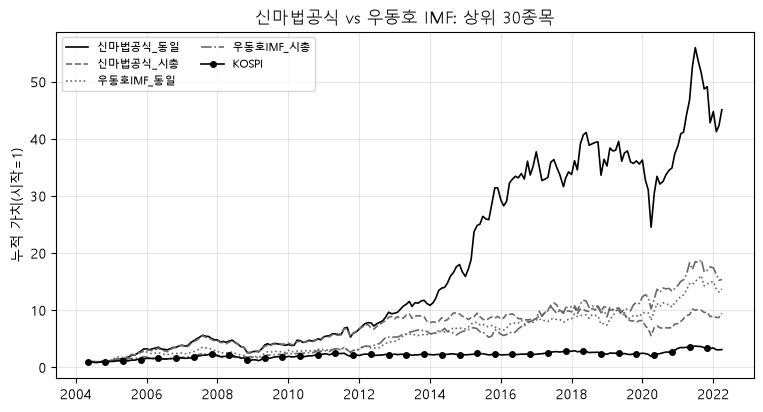

In [5]:
평가.누적그림(R, "신마법공식 vs 우동호 IMF: 상위 30종목");

## 6. 확인: 연도별 단계별 종목 수·빈칸으로 빠진 수·편입 수·WICS 금융 수

In [6]:
pd.concat({k: o["기록"] for k, o in 결과.items()}, axis=1).T

기준일               2004-04-01  2005-04-01  2006-04-03  2007-04-02  2008-04-01  2009-04-01  2010-04-01  2011-04-01  2012-04-02  2013-04-01  2014-04-01  2015-04-01  2016-04-01  2017-04-03  2018-04-02  2019-04-01  \
신마법공식  가격있음             1570        1583        1633        1704        1772        1801        1798        1809        1813        1777        1776        1820        1926        1986        2038        2115   
       시장               1570        1583        1633        1704        1772        1801        1798        1809        1813        1777        1776        1820        1926        1986        2038        2115   
       쓰지말것             1569        1582        1632        1703        1771        1800        1797        1808        1812        1776        1776        1820        1926        1986        2038        2115   
       보통주              1569        1582        1632        1703        1771        1800        1797        1808        1812        1776        1776        1820        1926        1986        2038        2115   
       금융업              1486        1505        1557        1628        1696        1726        1717        1710        1721        1705        1711        1729        1800        1862        1849        1914   
       투자기구             1480        1483        1521        1579        1647        1680        1671        1668        1679        1661        1672        1703        1776        1839        1839        1902   
       결산월              1372        1399        1441        1505        1567        1603        1601        1607        1625        1613        1630        1661        1739        1802        1806        1867   
       거래정지             1334        1348        1402        1476        1524        1505        1534        1569        1579        1568        1597        1630        1707        1766        1768        1808   
       빈칸:BP               3           4           4           4           4           3           5          11           1           2           1           1           1           1           1           2   
       빈칸:GPA              3           4           4           4           4           3           5          11           1           2           1           1           2           2           2           3   
       빈칸으로 빠짐             3           4           4           4           4           3           5          11           1           2           1           1           2           2           2           4   
       편입:상위30            30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30   
       확인:업종빈칸           368         376         406         428         449         423         432         439         427         413         421         425         455         462         473         458   
       확인:WICS금융           0           0           1           1           2           3           2           2           2           2           3           3           7           4           9          11   
우동호IMF 가격있음             1570        1583        1633        1704        1772        1801        1798        1809        1813        1777        1776        1820        1926        1986        2038        2115   
       시장               1570        1583        1633        1704        1772        1801        1798        1809        1813        1777        1776        1820        1926        1986        2038        2115   
       쓰지말것             1569        1582        1632        1703        1771        1800        1797        1808        1812        1776        1776        1820        1926        1986        2038        2115   
       보통주              1569        1582        1632        1703        1771        1800        1797        1808        1812        1776        1776        1820        1926        1986

## 7. 참고: Novy-Marx(2013) 표 7 Panel C 설정
원문: 비금융 대형주 500(GP/A·B/M이 모두 있는 종목), 두 순위의 평균, 상위 150 / 중간 200 / 하위 150, 동일가중, 매년 6월 말 리밸런싱, 회계자료는 다음 해 6월 말부터.
우리: 6월 마지막 거래일, 시총 상위 500(비금융), 3등분, 동일·시총가중. 재무 시점은 6월 말 리밸런싱이라 '발표일' 규칙(발표일 다음 거래일, 없으면 결산일 + 150일, 근거는 02 노트북 발표 지연 통계).

In [7]:
nm = {**포.기본설정, "이름": "NovyMarx2013_표7C", "시장": ["KS", "KQ"], "기간": ("2004-06", 기간[1]), "기준일": "마지막거래일",
      "리밸런싱": 12, "재무시점": ("발표일", 150), "제외": ["금융업", "투자기구", ("시총상위", {"n": 500})],
      "지표": [("GPA", "높게"), ("BP", "높게")], "합산": "순위합산", "고르기": ("분위", 3),
      "비중": ["동일", "시총"], "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)}
o = 포.실행(nm)
Fn = 평가.요인(포.기준일(nm), nm)
N = pd.DataFrame({f"{b}_{g}": o["수익률"][(b, g)] for b, g in o["수익률"]})
N["동일_H-L"], N["시총_H-L"] = N["동일_Q1"] - N["동일_Q3"], N["시총_Q1"] - N["시총_Q3"]
N = N.dropna(how="all")
표N = 평가.성과표(N, Fn, ["동일_H-L", "시총_H-L"])
display(표N)
display(o["기록"].T)
원문 = pd.DataFrame({"월 초과수익(%)": [0.78, 0.64], "t": [3.68, 5.21], "FF3 α(%)": [0.16, 0.39], "FF3 t": [2.69, 3.77]}, index=["High", "H-L"])
우리 = pd.DataFrame({"월 초과수익(%)": 표N.loc[["동일_Q1", "동일_H-L"], "초과평균 α(월)"].to_numpy() * 100,
                   "t": 표N.loc[["동일_Q1", "동일_H-L"], "초과평균 t(OLS)"].to_numpy(),
                   "FF3 α(%)": 표N.loc[["동일_Q1", "동일_H-L"], "FF3 α(월)"].to_numpy() * 100,
                   "FF3 t": 표N.loc[["동일_Q1", "동일_H-L"], "FF3 t(OLS)"].to_numpy()}, index=["High", "H-L"])
pd.concat({"원문(미국 1963-07~2009-12)": 원문, "우리": 우리}, axis=1).swaplevel(axis=1)[list(원문)]

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW)
동일_Q1,214.0000,11.1569,0.1504,0.1992,0.6835,-0.5061,0.6927,0.0114,2.8863,2.5480,0.0066,3.0892,2.8432,0.0036,2.1631,2.4697,0.0031,1.8690,2.0527
동일_Q2,214.0000,4.5533,0.1009,0.2169,0.4408,-0.5351,0.3223,0.0080,1.8613,1.7086,0.0026,1.2400,1.3080,0.0010,0.6626,0.7363,0.0007,0.4282,0.4573
동일_Q3,214.0000,0.3572,0.0173,0.2466,0.0976,-0.6446,-0.2656,0.0020,0.4121,0.3934,-0.0038,-1.3939,-1.3586,-0.0015,-0.7837,-0.8913,-0.0023,-1.2407,-1.2923
시총_Q1,214.0000,10.0882,0.1444,0.1774,0.7133,-0.3548,0.7454,0.0106,3.0121,2.8479,0.0061,3.6528,3.7714,0.0051,2.9380,2.9423,0.0056,3.2671,3.2997
시총_Q2,214.0000,3.0526,0.0816,0.1758,0.3952,-0.4144,0.1281,0.0058,1.6691,1.5837,0.0012,0.9134,0.9603,0.0015,1.1078,1.1819,0.0013,0.9874,1.1411
시총_Q3,214.0000,1.2125,0.0455,0.2461,0.2078,-0.6338,-0.0807,0.0043,0.8775,0.8531,-0.0019,-0.7925,-0.7856,0.0022,1.0258,1.0135,0.0010,0.4759,0.4590
동일_H-L,214.0000,5.4633,0.1103,0.1190,0.9422,-0.2941,0.1082,0.0093,3.9788,4.0095,0.0104,4.6407,4.4125,0.0051,2.8591,3.0042,0.0054,3.0384,3.2982
시총_H-L,214.0000,1.8027,0.0595,0.1876,0.4026,-0.4466,-0.0338,0.0063,1.7002,1.7718,0.0080,2.2654,2.3388,0.0029,0.8418,0.8548,0.0046,1.4089,1.4200


기준일,2004-06-30,2005-06-30,2006-06-30,2007-06-29,2008-06-30,2009-06-30,2010-06-30,2011-06-30,2012-06-29,2013-06-28,2014-06-30,2015-06-30,2016-06-30,2017-06-30,2018-06-29,2019-06-28,2020-06-30,2021-06-30
가격있음,1552,1557,1648,1708,1779,1776,1768,1800,1794,1759,1771,1842,1931,1993,2044,2126,2199,2309
시장,1552,1557,1648,1708,1779,1776,1768,1800,1794,1759,1771,1842,1931,1993,2044,2126,2199,2309
쓰지말것,1547,1555,1646,1705,1773,1770,1761,1794,1792,1752,1763,1841,1923,1991,2044,2123,2198,2309
금융업,1464,1480,1571,1629,1698,1695,1678,1696,1705,1683,1694,1738,1797,1868,1856,1945,2025,2122
투자기구,1459,1457,1531,1583,1652,1654,1637,1658,1663,1647,1664,1712,1782,1858,1845,1936,2015,2106
시총상위,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500
빈칸:GPA,4,2,3,3,5,3,1,7,1,1,1,3,3,6,1,1,5,10
빈칸:BP,4,2,3,3,5,3,1,8,1,1,1,3,2,6,1,0,3,4
빈칸으로 빠짐,4,2,3,3,5,3,1,8,1,1,1,3,3,6,1,1,5,10
편입:Q1,165,166,166,166,165,166,166,164,166,166,166,166,166,165,166,166,165,163


월 초과수익(%)                             t                      FF3 α(%)                         FF3 t       
     원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리
High                 0.7800 1.1355                 3.6800 2.8863                 0.1600 0.3555                 2.6900 2.1631
H-L                  0.6400 0.9346                 5.2100 3.9788                 0.3900 0.5068                 3.7700 2.8591

## 8. 차이 이유 후보
- **신마법공식**: 책 원문이 없어 원문 숫자와 비교할 수 없다. 우동호 IMF와의 차이는 EY 대신 PBR을 쓴 것뿐이다.
- **Novy-Marx 참고판**: 시장·기간(미국 1963~2009 vs 한국), BM 분모(원문은 6개월 늦춘 시가, 우리는 그날 시가총액), 장부가 정의(원문은 자본 + 이연법인세 − 우선주, 우리는 자본총계(지배)), 3묶음 크기(150/200/150 vs 3등분).
- **벤치마크**: 신마법공식은 수정주가(배당 미포함)라 코스피 가격지수와 정의가 맞다. Novy-Marx 참고판은 TR 가격이라 정보비율·CAPM α가 배당만큼 높게 나온다.

## 9. 원문과 다르게 한 것
| 항목 | 원문·정의 | 우리 | 이유 |
|---|---|---|---|
| 책 원문(강환국 2017 10장) | 미확인 | 정의는 2차 인용, 나머지는 우동호 IMF 설정 | 책 숫자를 지어내지 않기 |
| PBR 순위 | PBR 낮을수록 좋음 | BP(PBR 역수) 높을수록 좋음 | 자본이 음수인 종목은 PBR이 음수라 '가장 싼 쪽'에 줄 서는 것 막기. 자본이 양수인 종목끼리는 순서가 같음 |
| Novy-Marx 대형주 500 | GP/A·BM 둘 다 있는 비금융 500 | 비금융 시총 500을 먼저 고른 뒤 빈칸 제외 | 공통/의 거르기 순서(거르기 → 지표) |
| Novy-Marx 묶음 크기 | 150/200/150 | 3등분 | `고르기`는 같은 크기 분위만 지원 |
| 상장 구간 | 상장 종목 | 시장구분(CP10000300)이 코스피·코스닥('KS'·'KQ')인 날의 가격만 계산에 씀(`읽기.상장가격`). 원본 값은 그대로 | 통합_확인기록 F2(상장일보다 앞선 가격 = 이전상장 전 시장 가격)·F3(상장폐지 뒤 장외 가격). 회원 결정 2026-11-02 |
| '쓰지 말 것' 칸 | — | README_데이터의 '쓰지 말 것' 구간이 [리밸런싱일, 다음 리밸런싱일]에 걸리면 편입 대상에서 뺌(`종목거르기.쓰지말것`, 항상 `시장` 다음 단계). 직전 12개월 일간수익률에서도 빈칸으로 봄. 값은 그대로 | A008080 2004-01~2013-09(D-05, 재조회 R28도 값 같음), 수정주가 병합·감자 미반영 7칸의 그 달(D27), 배당 포함 가격(TR)을 쓸 때 TR 이상칸 107칸의 앞날~그날(D-06·U3). 회원 결정 2026-11-02 |
| 호텔신라(A008770) FY2023 | — | 매출원가·매출총이익을 빈칸으로 봄 → 그해 GP/A 등에서 제외(값은 그대로, `지표.빈칸으로볼칸`) | 판본마다 값이 다름(R29 재조회는 매출원가 0, 10월 파일은 1,418,625,926천원). 통합_확인기록 F1. 회원 결정 2026-11-02 |
| 끝 날짜 | — | 모든 일간 항목에 값이 있는 마지막 날(`읽기.공통끝`)에서 자름 | 통합_확인기록 F6(항목마다 끝 날짜가 다름) |
| 코드 재사용 16종목 | — | 재사용 경계를 넘는 수익률을 쓰지 않음(공백 구간이 빈칸이라 끊김, 01 노트북 11절에서 확인). 직전 12개월 상장 판정도 시장구분으로 함 | 통합_확인기록 F5, README_데이터 D-04 |
| 같은 회계연도 두 결산월 | — | 결산일이 늦은 행 | 통합_확인기록 F9(A432320) |


## 10. 요약표용 저장
4절 상위 30 포트폴리오(EW·VW)의 월수익률을 `결과_월수익률/`에 남긴다.

In [8]:
R2 = R.drop(columns="KOSPI")
R2.columns = pd.MultiIndex.from_tuples([tuple(c.rsplit("_", 1)) for c in R2])
평가.저장(R2, F, "04_신마법공식")
list(R2)

[('신마법공식', '동일'), ('신마법공식', '시총'), ('우동호IMF', '동일'), ('우동호IMF', '시총')]